**ANOMALY DETECTION PCA-MD**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import shutil

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:

versione = "v1"            # "v1" oppure "v3"
punto = "proj_raw"         # "encoder" | "pre_proj" | "post_proj"
pca = None                 # None per encoder e post_proj, 0.99 per pre_proj


modelli = {
    "v1": {"moco_version": "net_v3", "moco_attn": False,
           "simple_proj": False, "pool_grid": 4, "attn": False}, 
    "v2": {"moco_version": "v2", "moco_attn": True, "ltae": True, "spac_net": False,
            "simple_proj": False, "pool_grid": 4, "attn": False},               
    "v3": {"moco_version": "v4", "moco_attn": True, "ltae": True, "spac_net": False,
            "simple_proj": False, "pool_grid": 4, "attn": False},      
}

parameters = {
    "job_name": f"{versione}_{punto}",
    "feature_point": punto,
    "pca_components": pca,
    **modelli[versione],
    "dataset_standard": "Standard",
    "dataset_anomalies": "Floods_Anomalies_v3_crop_norm",
    "min_flood_area": 0.0,
    "n_series_thr": 500,
    "standardize": True,
    "hidden_channels_dim": 64,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,
    "n_images2": 4, "n_channels2": 10,
    "batch_size": 16,
    "workers": 0,
    "save_embeddings": False,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "200Gi"}
    }
]

**BUILD ENVIRONMENT**

In [8]:
md_func = project.new_function(
    name=f'md_features',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly:ad_md_features",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [ ]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = md_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection md: {run_ad.id}")

2026-10-26 16:11:23,884 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7ceeb98b2dc3455eada87b02a3855f51 to finish...
2026-10-26 16:11:28,891 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7ceeb98b2dc3455eada87b02a3855f51 to finish...
2026-10-26 16:11:33,900 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7ceeb98b2dc3455eada87b02a3855f51 to finish...
2026-10-26 16:11:38,914 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7ceeb98b2dc3455eada87b02a3855f51 to finish...
2026-10-26 16:11:43,923 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7ceeb98b2dc3455eada87b02a3855f51 to finish...
2026-10-26 16:11:48,934 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7ceeb98b2dc3455eada87b02a3855f51 to finish...
2026-10-26 16:11:53,948 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 7ceeb98b2dc3455eada87b02a3855f51 to finish...
2026-10-26 16

In [ ]:
job_name = "v2_encoder"                                   

RESULTS_DIR = f"/tmp/anomaly_results_mdf_{job_name}"       
shutil.rmtree(RESULTS_DIR, ignore_errors=True)

zip_path = project.get_artifact(f"anomaly_results_mdf_{job_name}").download(f"{RESULTS_DIR}.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]["score"]
score_anom = df[df.label == 1]["score"]

print(f"job: {results['job_name']} | moco: {results['moco_version']} | punto: {results['feature_point']}", "\n")
print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"PCA: {results['n_componenti']} componenti (pca_components={results['pca_components']}) | standardize={results['standardize']}")
print(f"min_flood_area = {results['min_flood_area']:.3f}")
print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}", "\n")
print(f"AUROC (score basso = anomalia): {results['auroc']:.3f}")

# AUROC per fascia di area allagata
for fascia, r in results["auroc_fasce"].items():
    print(f"  fascia {fascia:8s}: AUROC {r['auroc']:.3f} ({r['n_anomale']} anomale)")

df_rules = pd.DataFrame(results["rules"]).T
df_rules

job: v2_encoder | moco: v2 | punto: encoder 

n_fit: 2072 | n_thr: 500 | n_normali: 2402 | n_anomale: 2402 

PCA: 512 componenti (pca_components=None) | standardize=True
min_flood_area = 0.000
score normali: -690.1082 ± 226.1732
score anomale: -988.2824 ± 349.1810 

AUROC (score basso = anomalia): 0.771
  fascia 0-5%    : AUROC 0.589 (331 anomale)
  fascia 5-20%   : AUROC 0.706 (986 anomale)
  fascia 20-100% : AUROC 0.885 (1085 anomale)


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
score < FA 5%),-1113.118997,769.0,116.0,1633.0,2286.0,0.048293,0.679850,0.320150,0.868927,0.467904
score < FA 10%),-994.434030,1016.0,211.0,1386.0,2191.0,0.087843,0.577019,0.422981,0.828036,0.559934
score < FA 15%),-903.372388,1288.0,356.0,1114.0,2046.0,0.148210,0.463780,0.536220,0.783455,0.636678
score < FA 20%),-841.216543,1436.0,492.0,966.0,1910.0,0.204829,0.402165,0.597835,0.744813,0.663279
score < FA 25%),-804.044734,1539.0,600.0,863.0,1802.0,0.249792,0.359284,0.640716,0.719495,0.677824
score < FA 30%),-757.684221,1685.0,744.0,717.0,1658.0,0.309742,0.298501,0.701499,0.693701,0.697578


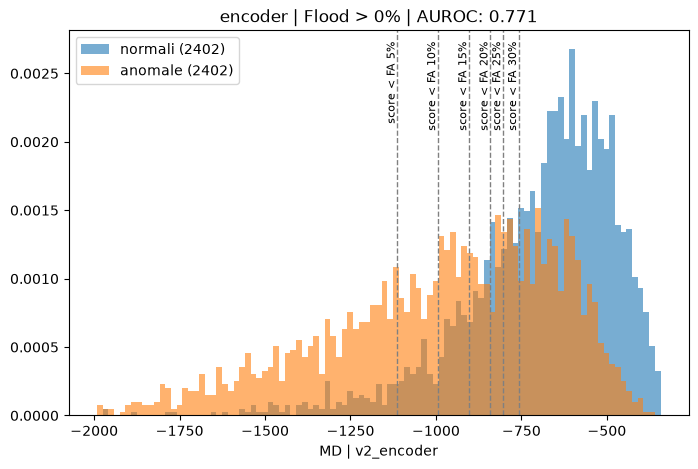

In [ ]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

lo, hi = np.quantile(df.score, [0.005, 0.995])                  
bins = np.linspace(lo, hi, 100)

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=bins, alpha=0.6, density=True, color="tab:blue", label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=bins, alpha=0.6, density=True, color="tab:orange", label=f"anomale ({len(score_anom)})")
for nome, r in results['rules'].items():                         
    if lo <= r["soglia"] <= hi:
        plt.axvline(x=r["soglia"], color='gray', linestyle='--', linewidth=1)
        plt.text(r["soglia"], plt.ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"), rotation=90, va="top", ha="right", fontsize=8)   
plt.xlabel(f"MD | {job_name}")
plt.legend(loc="upper left")
plt.title(f"{results['feature_point']} | Flood > {results['min_flood_area']:.0f}% | AUROC: {results['auroc']:.3f}")
plt.show()

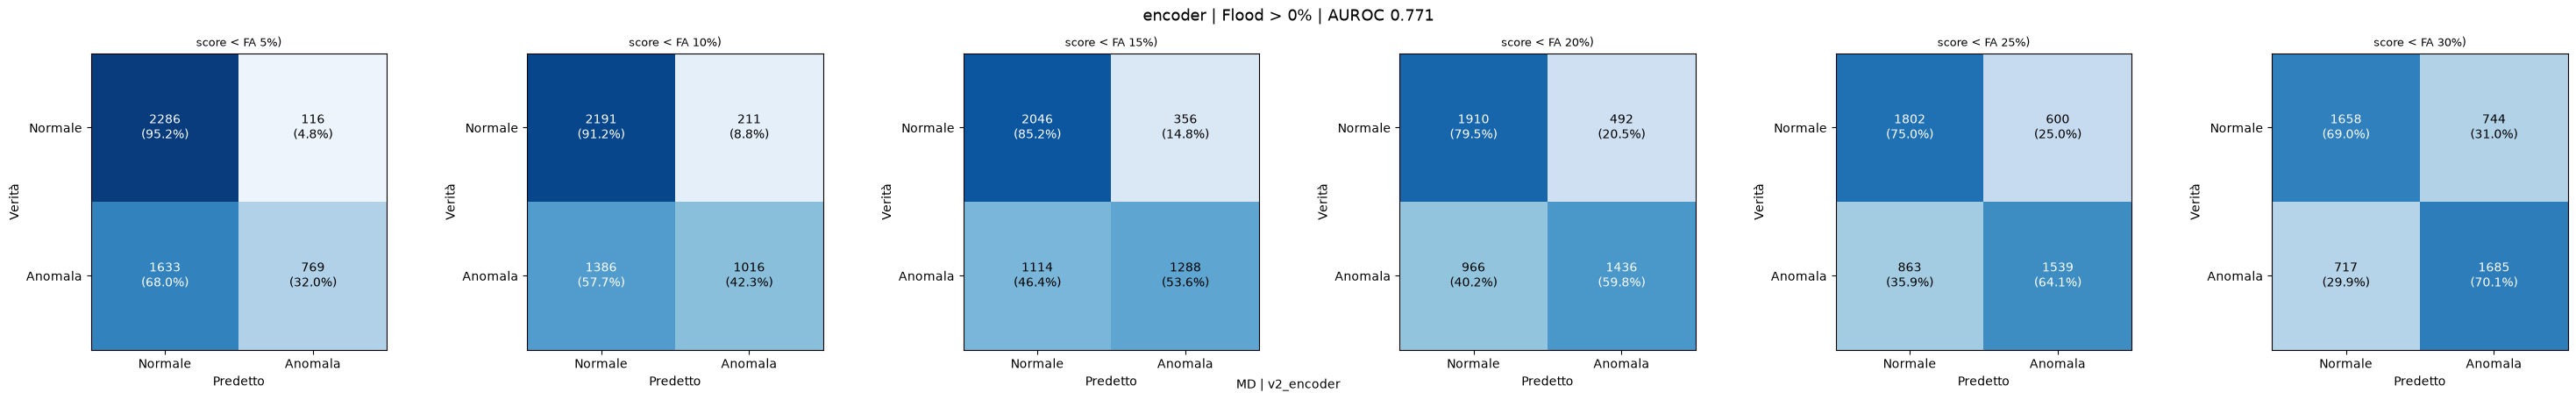

In [ ]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

fig.suptitle(f"{results['feature_point']} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)     
fig.text(0.5, 0.01, f"MD | {job_name}", ha="center", va="bottom", fontsize=10)       

plt.tight_layout()
plt.show()